# 03 · Discovering positions, and what information carries value

The dataset has **no position column**, but role-based questions (what is a striker or a defender paid for?) need one. Here we:

1. **Recover positions unsupervised** from each player's attribute profile.
2. Run **ablations**: does club, nationality or position add anything beyond the attributes? How few numbers do we need?

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.compose import make_column_transformer
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import silhouette_score
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder

warnings.filterwarnings("ignore")
d = pd.read_csv("../data/player_stats_clean.csv")
SKILLS = [c for c in d.columns[6:] if c not in ("value", "value_m", "log_value", "is_gk")]
OUTFIELD_SKILLS = [c for c in SKILLS if not c.startswith("gk_")]
CV = KFold(5, shuffle=True, random_state=42)

## 1. Role discovery

The key move is to **centre each player on their own average** before clustering. Otherwise k-means just splits good players from bad ones. After centring, the clusters capture *what kind* of player someone is (finishing high relative to their own level, tackling high, and so on), not *how good*.

In [2]:
outf = d[d.is_gk == 0]
centred = outf[OUTFIELD_SKILLS].sub(outf[OUTFIELD_SKILLS].mean(axis=1), axis=0)
Z = StandardScaler().fit_transform(centred)

sil = {k: silhouette_score(Z, KMeans(k, n_init=10, random_state=0).fit_predict(Z), sample_size=3000, random_state=0)
       for k in range(3, 10)}
pd.Series(sil, name="silhouette").to_frame().T.round(3)

,3,4,5,6,7,8,9
silhouette,0.171,0.162,0.151,0.133,0.12,0.109,0.101


Silhouette falls gently with k: roles form a continuum (a fullback is partly a winger), so k is chosen for **interpretability**. k = 6 is the largest k where every cluster has a distinct, football-meaningful signature.

In [3]:
km = KMeans(6, n_init=20, random_state=0).fit(Z)
prof = centred.groupby(km.labels_).mean()
prof = prof - prof.mean()
prof.apply(lambda r: ", ".join(r.nlargest(5).index), axis=1).to_frame("most distinctive attributes")

,most distinctive attributes
0,"acceleration, agility, sprint_speed, balance, ..."
1,"interceptions, stand_tackle, slide_tackle, lon..."
2,"slide_tackle, stand_tackle, interceptions, sta..."
3,"finishing, volleys, penalties, att_position, h..."
4,"slide_tackle, stand_tackle, interceptions, str..."
5,"fk_acc, curve, vision, long_shots, finishing"


Name each cluster by matching it to football role signatures (greedy best match):

In [4]:
SIGNATURES = {
    "Striker": ["finishing", "att_position", "volleys", "penalties"],
    "Winger": ["agility", "acceleration", "balance", "sprint_speed"],
    "Playmaker": ["curve", "fk_acc", "long_shots", "vision"],
    "Defensive mid": ["interceptions", "aggression", "long_pass", "stand_tackle"],
    "Centre-back": ["strength", "stand_tackle", "slide_tackle", "heading", "jumping"],
    "Fullback": ["acceleration", "slide_tackle", "crossing", "stamina"],
}
scores = sorted(((prof.loc[c, sig].mean(), c, n) for c in prof.index for n, sig in SIGNATURES.items()), reverse=True)
names = {}
for _, c, n in scores:
    if c not in names and n not in names.values():
        names[c] = n
d["role"] = "Goalkeeper"
d.loc[outf.index, "role"] = [names[c] for c in km.labels_]

known = ["Kylian Mbappé", "Erling Haaland", "Kevin De Bruyne", "Mohamed Salah", "Bukayo Saka", "Virgil van Dijk",
         "Rodri", "Joshua Kimmich", "Gianluigi Donnarumma"]
d[d.player.isin(known)][["player", "club", "role"]].set_index("player")

,club,role
player,,
Bukayo Saka,Arsenal,Playmaker
Erling Haaland,Manchester City,Striker
Gianluigi Donnarumma,Paris SG,Goalkeeper
Virgil van Dijk,Liverpool,Centre-back
Kevin De Bruyne,Manchester City,Playmaker
Joshua Kimmich,FC Bayern München,Defensive mid
Kylian Mbappé,Paris SG,Striker
Rodri,Manchester City,Defensive mid
Mohamed Salah,Liverpool,Playmaker


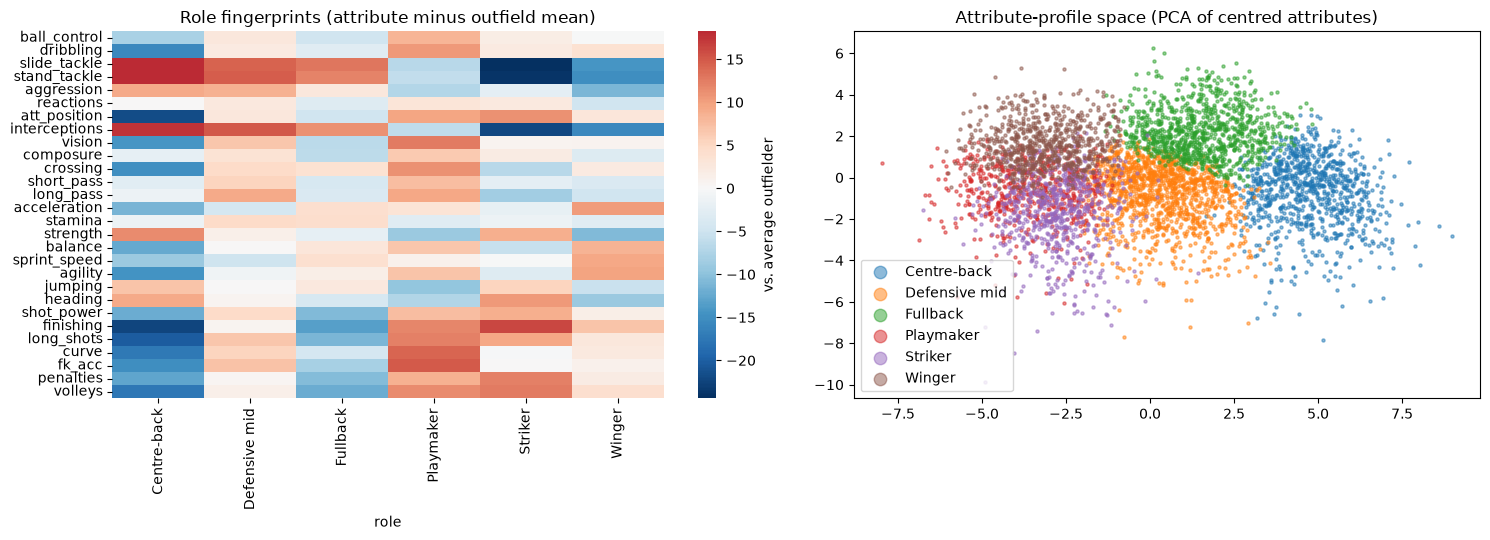

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
heat = d[d.is_gk == 0].groupby("role")[OUTFIELD_SKILLS].mean()
heat = heat.sub(heat.mean())
sns.heatmap(heat.T, cmap="RdBu_r", center=0, ax=ax[0], cbar_kws={"label": "vs. average outfielder"})
ax[0].set_title("Role fingerprints (attribute minus outfield mean)")
pc = PCA(2, random_state=0).fit_transform(Z)
for r in heat.index:
    m = d.loc[outf.index, "role"].values == r
    ax[1].scatter(pc[m, 0], pc[m, 1], s=5, alpha=0.5, label=r)
ax[1].legend(markerscale=4)
ax[1].set_title("Attribute-profile space (PCA of centred attributes)")
plt.tight_layout()

In [6]:
summary = d.groupby("role").agg(n=("player", "size"), median_value_m=("value_m", "median"),
                                top_value_m=("value_m", "max"), median_age=("age", "median"))
summary.sort_values("median_value_m", ascending=False).round(2)

,n,median_value_m,top_value_m,median_age
role,,,,
Playmaker,608,1.50,107.5,26.0
Striker,628,0.98,153.5,27.0
Defensive mid,1238,0.88,97.0,27.0
Centre-back,903,0.85,84.5,26.0
Fullback,941,0.60,27.5,25.0
Winger,727,0.60,28.0,24.0
Goalkeeper,632,0.38,78.0,27.0


## 2. Ablations: what information actually carries value?
Same booster and folds as 02. Club and nationality (683 clubs, 135 countries) are **target-encoded inside each fold**, so the encoder never sees the held-out player's value.

In [7]:
HGB = lambda: HistGradientBoostingRegressor(max_iter=1500, learning_rate=0.03, l2_regularization=1.0, random_state=0)
enc = lambda cols, e: make_pipeline(make_column_transformer((e, cols), remainder="passthrough"), HGB())
BASE = SKILLS + ["height", "weight", "age", "is_gk"]
y = d.log_value


def mape(p):
    a = np.abs(np.exp(p - y) - 1)
    return {"median_ape": np.median(a), "within_25": np.mean(a < .25),
            "r2_log": 1 - np.sum((p - y) ** 2) / np.sum((y - y.mean()) ** 2)}


setups = {
    "All attributes + age/height/weight (reference)": (HGB(), BASE),
    "+ club (target-encoded)": (enc(["club"], TargetEncoder(target_type="continuous")), BASE + ["club"]),
    "+ nationality (target-encoded)": (enc(["country"], TargetEncoder(target_type="continuous")), BASE + ["country"]),
    "+ discovered role": (enc(["role"], OneHotEncoder(sparse_output=False)), BASE + ["role"]),
    "no age": (HGB(), [c for c in BASE if c != "age"]),
    "no GK attributes": (HGB(), [c for c in BASE if not c.startswith("gk_")]),
    "reactions + composure + age": (HGB(), ["reactions", "composure", "age"]),
    "reactions + age": (HGB(), ["reactions", "age"]),
    "reactions only": (HGB(), ["reactions"]),
}
abl = pd.DataFrame({k: {"n_features": len(f), **mape(cross_val_predict(m, d[f], y, cv=CV))}
                    for k, (m, f) in setups.items()}).T
abl.style.format({"median_ape": "{:.1%}", "within_25": "{:.1%}", "r2_log": "{:.3f}", "n_features": "{:.0f}"})

,n_features,median_ape,within_25,r2_log
All attributes + age/height/weight (reference),37,12.5%,79.9%,0.971
+ club (target-encoded),38,12.6%,80.2%,0.971
+ nationality (target-encoded),38,12.4%,79.7%,0.971
+ discovered role,38,12.4%,80.3%,0.971
no age,36,16.9%,67.9%,0.919
no GK attributes,32,13.6%,75.2%,0.956
reactions + composure + age,3,35.3%,36.8%,0.807
reactions + age,2,37.4%,34.5%,0.773
reactions only,1,38.8%,33.0%,0.717


### Club premium, checked a second way
If clubs paid premiums, players at big clubs would have systematically **positive** residuals from the attribute-only model. Compare the mean out-of-fold residual per club, for clubs with ≥ 8 players in the data:

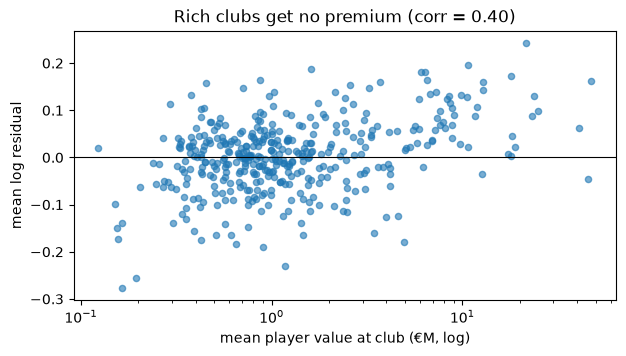

In [8]:
oof = pd.read_csv("../data/oof_predictions.csv")["oof_blend"]
d["resid"] = d.log_value - oof
club = d.groupby("club").agg(n=("resid", "size"), mean_resid=("resid", "mean"), mean_value_m=("value_m", "mean"))
club = club[club.n >= 8]
r = np.corrcoef(np.log(club.mean_value_m), club.mean_resid)[0, 1]
ax = club.plot.scatter("mean_value_m", "mean_resid", logx=True, figsize=(7, 3.5), alpha=0.6,
                       title=f"Rich clubs get no premium (corr = {r:.2f})")
ax.axhline(0, color="k", lw=0.8)
ax.set(xlabel="mean player value at club (€M, log)", ylabel="mean log residual");

## Takeaways

* **Club and nationality add nothing.** Given a player's attributes and age, playing for Real Madrid or Rochdale doesn't change the price. **FIFA 24 value is a formula on the player card, not a market price.** A real-world transfer model would look very different, and this is the main caveat on any "business" reading of this project.
* **One attribute, `reactions`, explains ~72% of log-value variance on its own.** It is the closest stand-in for the card's hidden *overall rating*. Adding age takes that to ~78%.
* **Age is the second axis.** Dropping it costs more than any other single change.
* The discovered role helps a little. The boosting model already infers role from the attributes.

In [9]:
d[["player", "club", "age", "role"]].to_csv("../data/roles.csv", index=False)